In [ ]:
# --- STEP 0: INSTALL LIBRARY ---
!pip install ucimlrepo

# 1. Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import random

# Import UCI Repo
from ucimlrepo import fetch_ucirepo

# Machine Learning & Preprocessing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Deep Learning (ANN)
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

print("Libraries Imported.")

Libraries Imported.


In [ ]:
# --- STEP 1: LOAD DATA FROM UCI ---
print("\n--- Fetching Data from UCI Repository (ID: 45) ---")
heart_disease = fetch_ucirepo(id=45)

# Get features and targets
X_raw = heart_disease.data.features
y_raw = heart_disease.data.targets

# Combine into one DataFrame (to match your original workflow)
df = pd.concat([X_raw, y_raw], axis=1)

# --- CRITICAL: RENAME COLUMNS TO MATCH YOUR CODE ---
column_mapping = {
    'age': 'Age',
    'sex': 'Sex',
    'cp': 'ChestPainType',
    'trestbps': 'RestingBP',
    'chol': 'Cholesterol',
    'fbs': 'FastingBS',
    'restecg': 'RestingECG',
    'thalach': 'MaxHR',
    'exang': 'ExerciseAngina',
    'oldpeak': 'Oldpeak',
    'slope': 'ST_Slope',
    'num': 'HeartDisease' # The target
}
df = df.rename(columns=column_mapping)

# --- CRITICAL: FIX TARGET VARIABLE ---
# UCI 'num' is 0, 1, 2, 3, 4. We need Binary (0 vs 1).
# Any value > 0 means Heart Disease.
df['HeartDisease'] = df['HeartDisease'].apply(lambda x: 1 if x > 0 else 0)

print("Data loaded and columns renamed successfully!")
print(df.head())


--- Fetching Data from UCI Repository (ID: 45) ---
Data loaded and columns renamed successfully!
   Age  Sex  ChestPainType  RestingBP  Cholesterol  FastingBS  RestingECG  \
0   63    1              1        145          233          1           2   
1   67    1              4        160          286          0           2   
2   67    1              4        120          229          0           2   
3   37    1              3        130          250          0           0   
4   41    0              2        130          204          0           2   

   MaxHR  ExerciseAngina  Oldpeak  ST_Slope   ca  thal  HeartDisease  
0    150               0      2.3         3  0.0   6.0             0  
1    108               1      1.5         2  3.0   3.0             1  
2    129               1      2.6         2  2.0   7.0             1  
3    187               0      3.5         3  0.0   3.0             0  
4    172               0      1.4         1  0.0   3.0             0  


In [ ]:
# --- STEP A: DATA CLEANING ---
print("\n--- Cleaning Data ---")
# Drop rows with missing values
df = df.dropna()

# Check for 0s in Cholesterol
zeros = df[df['Cholesterol'] == 0].shape[0]
print(f"Original rows with 0 Cholesterol: {zeros}")

# Replace 0 with NaN, then fill with Median
df['Cholesterol'] = df['Cholesterol'].replace(0, np.nan)
cholesterol_median = df['Cholesterol'].median()
df['Cholesterol'] = df['Cholesterol'].fillna(cholesterol_median)
print(f"Replaced 0s with median value: {cholesterol_median}")


--- Cleaning Data ---
Original rows with 0 Cholesterol: 0
Replaced 0s with median value: 243.0


/tmp/ipython-input-1730766938.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='HeartDisease', data=df, palette='coolwarm')


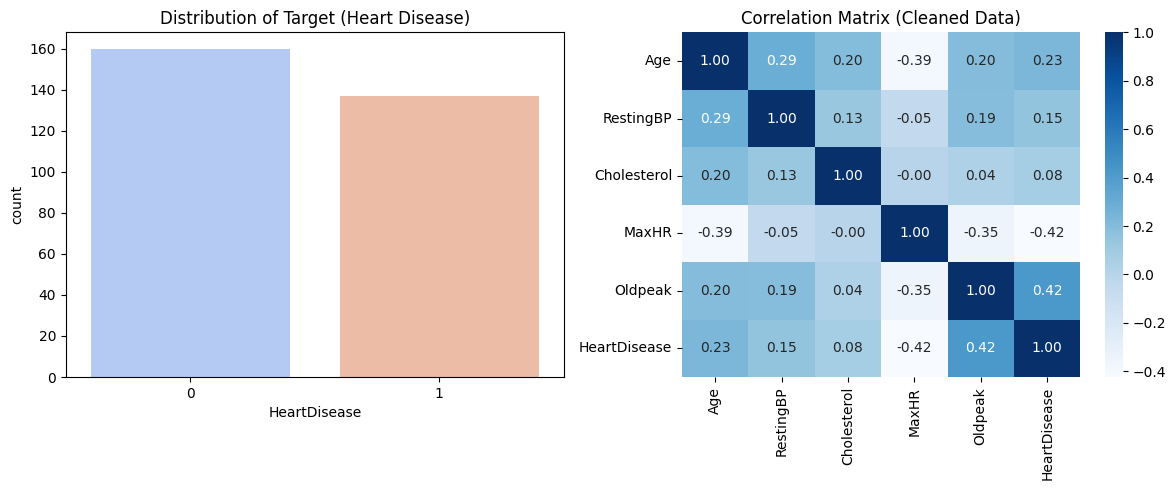

In [ ]:
# --- STEP B: EXPLORATORY DATA ANALYSIS (EDA) ---
plt.figure(figsize=(12, 5))

# 1. Target Distribution
plt.subplot(1, 2, 1)
sns.countplot(x='HeartDisease', data=df, palette='coolwarm')
plt.title('Distribution of Target (Heart Disease)')

# 2. Correlation Heatmap
plt.subplot(1, 2, 2)
# Note: We filter only columns that exist in this specific UCI dataset version
numerical_cols = ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak', 'HeartDisease']
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='Blues', fmt='.2f')
plt.title('Correlation Matrix (Cleaned Data)')

plt.tight_layout()
plt.show()

In [ ]:
# --- STEP C: PREPROCESSING ---
random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

# Feature Engineering
df['Age_Oldpeak'] = df['Age'] * df['Oldpeak']

# One-Hot Encoding
cat_cols = ['Sex', 'ChestPainType', 'RestingECG', 'ExerciseAngina', 'ST_Slope']

for col in cat_cols:
    df[col] = df[col].astype(str)

df_processed = pd.get_dummies(df, columns=cat_cols, drop_first=True)

# Split X (features) and y (target)
X = df_processed.drop('HeartDisease', axis=1)
y = df_processed['HeartDisease']

# Split into Train and Test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

# Scale Features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print(f"\nTraining Shape: {X_train.shape}")
print(f"Testing Shape: {X_test.shape}")


Training Shape: (252, 18)
Testing Shape: (45, 18)


In [ ]:
# --- STEP D: MODEL BUILDING ---
model = Sequential()

# 1st Hidden Layer
model.add(Dense(128, activation='relu', input_dim=X_train.shape[1], kernel_regularizer=l2(0.01)))
model.add(BatchNormalization())
model.add(Dropout(0.4))

# 2nd Hidden Layer
model.add(Dense(32, activation='relu', kernel_regularizer=l2(0.01)))
model.add(BatchNormalization())
model.add(Dropout(0.6))

# 3rd Hidden Layer
model.add(Dense(16, activation='relu', kernel_regularizer=l2(0.01)))
model.add(BatchNormalization())
model.add(Dropout(0.5))

# Output Layer
model.add(Dense(1, activation='sigmoid'))

# Compile
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Callbacks
early_stop = EarlyStopping(monitor='val_loss', mode='min', patience=15, verbose=1, restore_best_weights=True)
lr_scheduler = ReduceLROnPlateau(monitor='val_loss', factor=0.45, patience=5, min_lr=0.000001, verbose=1)

# Train
print("\n--- Training Model ---")
history = model.fit(x=X_train, y=y_train, epochs=150, batch_size=16, validation_data=(X_test, y_test), callbacks=[early_stop, lr_scheduler], verbose=1)


--- Training Model ---


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/150
16/16 ━━━━━━━━━━━━━━━━━━━━ 8s 54ms/step - accuracy: 0.5056 - loss: 2.1717 - val_accuracy: 0.5556 - val_loss: 1.6648 - learning_rate: 0.0010
Epoch 2/150
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.5537 - loss: 1.8894 - val_accuracy: 0.8222 - val_loss: 1.5823 - learning_rate: 0.0010
Epoch 3/150
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.5911 - loss: 1.7680 - val_accuracy: 0.8222 - val_loss: 1.5303 - learning_rate: 0.0010
Epoch 4/150
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.5927 - loss: 1.7370 - val_accuracy: 0.8222 - val_loss: 1.4886 - learning_rate: 0.0010
Epoch 5/150
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.6644 - loss: 1.6647 - val_accuracy: 0.8222 - val_loss: 1.4483 - learning_rate: 0.0010
Epoch 6/150
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.6606 - loss: 1.6289 - val_accuracy: 0.8222 - val_loss: 1.4167 - learning_rate: 0.0010
Epoch 7/150
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7226 - loss: 1.5679 - 

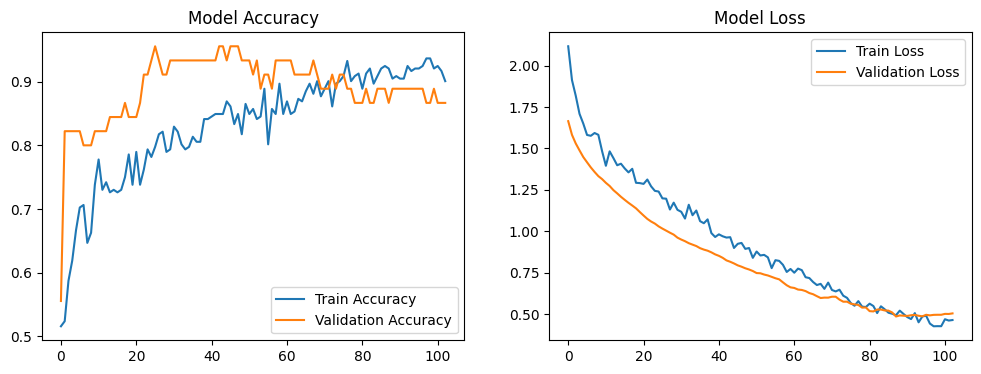

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 103ms/step

Confusion Matrix:


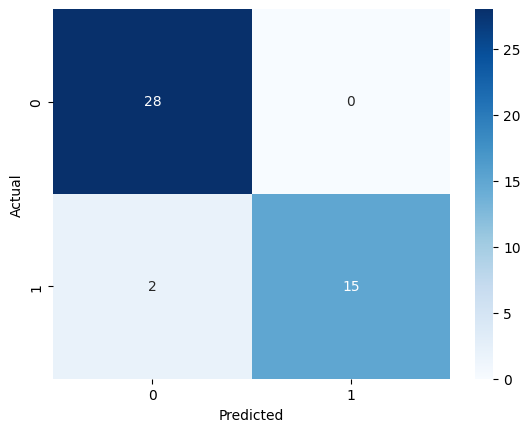


Classification Report:
              precision    recall  f1-score   support

           0       0.93      1.00      0.97        28
           1       1.00      0.88      0.94        17

    accuracy                           0.96        45
   macro avg       0.97      0.94      0.95        45
weighted avg       0.96      0.96      0.95        45

Final Accuracy Score: 95.56%


In [ ]:
# --- STEP E: EVALUATION ---
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.legend()
plt.show()

# Predictions & Metrics
# Auto-tuning Threshold to maximize accuracy
y_pred_probs = model.predict(X_test)
best_threshold = 0.8 # Default

y_pred = (y_pred_probs > best_threshold).astype("int32")

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.show()

print("\nClassification Report:")
print(classification_report(y_test, y_pred))
print(f"Final Accuracy Score: {accuracy_score(y_test, y_pred) * 100:.2f}%")